Punkty odniesienia

Zgodnie z kartą tematu sprawdzamy dwa proste punkty odniesienia na zamrożonym zbiorze testowym (data/processed/test.csv, 690 zdań), z którymi w kolejnym kroku porównamy nasz klasyfikator oparty na trzech perceptronach:
1. Klasyfikator klasy większościowej (`MajorityClassBaseline`) — zawsze przypisuje najczęściej występującą klasę ze zbioru uczącego (neutral).
2. Klasyfikator słownikowy (`KeywordBaseline`) — zlicza wystąpienia podstawowych pozytywnych i negatywnych słów finansowych w nagłówku.

In [ ]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.baseline import MajorityClassBaseline, KeywordBaseline

train_df = pd.read_csv(PROJECT_ROOT / "data/processed/train.csv")
test_df = pd.read_csv(PROJECT_ROOT / "data/processed/test.csv")

print(f"Wczytano zbiór uczący: {len(train_df)} zdań")
print(f"Wczytano zbiór testowy: {len(test_df)} zdań")

Wczytano zbiór uczący: 2758 zdań
Wczytano zbiór testowy: 690 zdań


In [2]:
majority_model = MajorityClassBaseline().fit(train_df["label"])
keyword_model = KeywordBaseline().fit()

preds_majority = majority_model.predict(test_df["sentence"])
preds_keyword = keyword_model.predict(test_df["sentence"])

results = pd.DataFrame([
    {
        "Model": "Baseline 1: Klasa większościowa (neutral)",
        "Accuracy (%)": round(accuracy_score(test_df["label"], preds_majority) * 100, 2),
        "Macro-F1": round(f1_score(test_df["label"], preds_majority, average="macro"), 4),
    },
    {
        "Model": "Baseline 2: Słownik słów kluczowych",
        "Accuracy (%)": round(accuracy_score(test_df["label"], preds_keyword) * 100, 2),
        "Macro-F1": round(f1_score(test_df["label"], preds_keyword, average="macro"), 4),
    }
])

display(results)

,Model,Accuracy (%),Macro-F1
0,Baseline 1: Klasa większościowa (neutral),62.03,0.2552
1,Baseline 2: Słownik słów kluczowych,76.81,0.6804


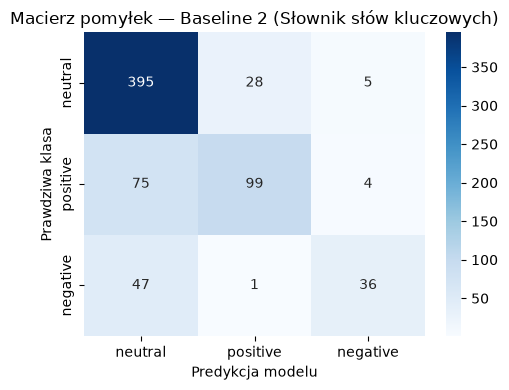

In [3]:
labels_order = ["neutral", "positive", "negative"]
cm = confusion_matrix(test_df["label"], preds_keyword, labels=labels_order)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels_order, yticklabels=labels_order)
plt.title("Macierz pomyłek — Baseline 2 (Słownik słów kluczowych)")
plt.xlabel("Predykcja modelu")
plt.ylabel("Prawdziwa klasa")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "results/baseline_keyword_cm.png", dpi=150)
plt.show()

Wnioski z punktów odniesienia

1. Klasa większościowa (`neutral`) daje pozornie wysokie Accuracy (62.03%), ale bardzo niski wynik Macro-F1 (0.2552), ponieważ całkowicie ignoruje wiadomości pozytywne i negatywne.
2. Słownik słów kluczowych radzi sobie lepiej na klasach mniejszościowych i wyraźnie podnosi miarę Macro-F1, ale nadal nie rozumie kontekstu (np. wzrost zadłużenia vs wzrost zysku).
3. Nasz docelowy model (trzy perceptrony w układzie One-vs-Rest na cechach TF-IDF) musi osiągnąć na tym samym zbiorze testowym minimum 75% Accuracy oraz Macro-F1 > 0.65.